# 03 — Pré-processamento das imagens

**TCC UNIP 2026** · Etapa 3 de 9 do pipeline · Seção 4.5.3 do trabalho escrito.

**Objetivo:** aplicar o DullRazor e o redimensionamento para 224 × 224 e dividir a base em treino, validação e teste, de forma estratificada e agrupada por lesão, com verificação de duplicidades perceptuais.

**Entradas:**
- `/content/data/processed/dataset_limpo.csv` (notebook 02)
- `/content/data/isic/<classe>/` (imagens originais)

**Saídas:**
- `train.csv`, `val.csv`, `test.csv` e as versões `*_sem_dullrazor.csv`
- imagens processadas em `processed/train|val|test/` e `processed/sem_dullrazor/`
- `split_audit.csv`, `perceptual_duplicates.csv`, `split_config.json`, `pipeline_config.json`
- figuras e análise do DullRazor

Antes de executar: no Colab, selecione *Ambiente de execução → Alterar tipo de ambiente de execução → GPU* (necessário a partir do notebook 05). As saídas exibidas foram preservadas da execução original do notebook único.

In [ ]:
# Parâmetro: True usa o Google Drive para guardar os arquivos entre notebooks;
# False usa só o disco da sessão atual. Quando o notebook é executado pelo
# 00_executar_todos.ipynb, vale o valor definido lá.
if "USAR_DRIVE" not in globals():
    USAR_DRIVE = True


In [ ]:
# ============================================================
# PERSISTÊNCIA ENTRE NOTEBOOKS (Google Drive)
# ============================================================
# Cada notebook roda em uma sessão própria do Colab. Para que os arquivos gerados por um
# notebook fiquem disponíveis para os seguintes, a pasta /content/data é ligada a uma
# pasta no Google Drive. O valor de USAR_DRIVE é definido na célula anterior.
PASTA_DRIVE = "/content/drive/MyDrive/TCC_UNIP/data"

import os
if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(PASTA_DRIVE, exist_ok=True)
    if not os.path.islink("/content/data"):
        if os.path.isdir("/content/data"):
            if os.listdir("/content/data"):
                raise RuntimeError("/content/data já contém arquivos: mova-os para a pasta do Drive antes de continuar.")
            os.rmdir("/content/data")
        os.symlink(PASTA_DRIVE, "/content/data")
print("Pasta de dados:", os.path.realpath("/content/data"))


In [ ]:
# [Célula reutilizada de 02_limpeza_analise_exploratoria.ipynb]
import os
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

In [ ]:
# [Célula reutilizada de 02_limpeza_analise_exploratoria.ipynb]
# ============================================================
# 2. LIMPEZA
# ============================================================

def identificar_coluna_id(df):
    """Detecta automaticamente qual coluna tem o identificador da imagem."""
    candidatos = ["isic_id", "image_id", "id", "name"]
    for c in candidatos:
        if c in df.columns:
            return c
    raise ValueError(f"Não achei coluna de ID. Colunas disponíveis: {list(df.columns)}")

### Pipeline de pré-processamento (item 3.4/3.5 do TCC):

- Particionamento estratificado em treino/validação/teste, priorizando `lesion_id`.
- Imagens sem `lesion_id` são mantidas como grupos individuais, salvo quando ligadas por duplicidade perceptual.
- Hash MD5 detecta arquivos binariamente idênticos; pHash identifica imagens visualmente semelhantes e impede que pares próximos caiam em conjuntos diferentes.
- DullRazor é aplicado conforme a variante experimental; redimensionamento e normalização são determinísticos.
- Aumento de dados aleatório é aplicado exclusivamente no treinamento; validação e teste não recebem augmentation aleatório.


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from tqdm import tqdm


In [ ]:
ENTRADA_CSV = "/content/data/processed/dataset_limpo.csv"
SAIDA_BASE = "/content/data/processed"
TAMANHO_IMAGEM = 224

In [ ]:
SEED = 42
PROPORCAO_TREINO = 0.70
PROPORCAO_VAL = 0.15
PROPORCAO_TESTE = 0.15

# Mantido por compatibilidade com a estrutura original. Na versão corrigida, imagens sem
# lesion_id são mantidas e viram grupos próprios, salvo quando ligadas por pHash a duplicatas.
INCLUIR_SEM_LESION_ID = True

In [ ]:
# ============================================================
# 1. DULLRAZOR — remoção de pelos e artefatos
# ============================================================
# Parâmetros centralizados (também são registrados no relatório de padronização)
DR_KERNEL = 9
DR_LIMIAR = 10
DR_RAIO_INPAINT = 3
PARAMS_JPEG = [int(cv2.IMWRITE_JPEG_QUALITY), 95]  # qualidade ao salvar (igual ao padrão do cv2)

def mascara_pelos(img_bgr, tamanho_kernel=DR_KERNEL, limiar=DR_LIMIAR):
    """Máscara binária (0/255) das estruturas escuras e finas (pelos), via Black-Hat morfológico."""
    cinza = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (tamanho_kernel, tamanho_kernel))
    blackhat = cv2.morphologyEx(cinza, cv2.MORPH_BLACKHAT, kernel)
    _, mascara = cv2.threshold(blackhat, limiar, 255, cv2.THRESH_BINARY)
    return mascara

def dullrazor(img_bgr, tamanho_kernel=DR_KERNEL, limiar=DR_LIMIAR):
    """
    Implementação clássica do DullRazor:
    1. Detecta estruturas escuras e finas (pelos) via Black-Hat morfológico.
    2. Binariza a máscara de pelos detectados.
    3. Usa inpainting para reconstruir a região onde havia pelo.
    """
    mascara = mascara_pelos(img_bgr, tamanho_kernel, limiar)
    resultado = cv2.inpaint(img_bgr, mascara, inpaintRadius=DR_RAIO_INPAINT, flags=cv2.INPAINT_TELEA)
    return resultado

def preprocessar_imagem(img_bgr, aplicar_dullrazor=True):
    """
    ÚNICA função de pré-processamento do projeto. Treino, validação e teste passam por ela
    com os mesmos parâmetros (garante filtragem idêntica nos três conjuntos).
      - aplicar_dullrazor=True  -> versão "tratada"  (DullRazor + resize)
      - aplicar_dullrazor=False -> versão "original" (só resize)
    """
    if aplicar_dullrazor:
        img_bgr = dullrazor(img_bgr)
    return cv2.resize(img_bgr, (TAMANHO_IMAGEM, TAMANHO_IMAGEM), interpolation=cv2.INTER_AREA)

In [ ]:
# ============================================================
# 2. SPLIT ESTRATIFICADO POR LESÃO + BLOQUEIO DE DUPLICIDADES PERCEPTUAIS
# ============================================================
# Política metodológica:
# 1) lesion_id é a chave principal de agrupamento (não patient_id).
# 2) Registros sem lesion_id são mantidos; cada um é grupo próprio, exceto se pHash
#    indicar semelhança perceptual com outra imagem, caso em que ambos ficam juntos.
# 3) Imagens com pHash próximo são agrupadas, nunca removidas automaticamente.
# 4) Não usar o conjunto de teste para selecionar hiperparâmetros.
import json

PHASH_DISTANCIA_MAX = 10  # pHash RGB de 192 bits + 15 bits de cor média quantizada (207 bits totais)
DISTANCIA_HIST_COR_MAX = 0.15  # confirmação adicional para evitar unir imagens só por fundo semelhante
ARQUIVO_AUDITORIA_SPLIT = os.path.join(SAIDA_BASE, "split_audit.csv")
ARQUIVO_DUPLICATAS_PERCEPTUAIS = os.path.join(SAIDA_BASE, "perceptual_duplicates.csv")


def calcular_phash(caminho):
    """pHash colorido de 192 bits (DCT por canal RGB) para reduzir colisões em fundos semelhantes."""
    try:
        img = cv2.imread(str(caminho), cv2.IMREAD_COLOR)
        if img is None:
            return None
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        # Assinatura espacial por canal (192 bits).
        reduzida = cv2.resize(img, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32)
        valor = 0
        for canal in range(3):
            dct = cv2.dct(reduzida[:, :, canal])
            bloco = dct[:8, :8].flatten()
            mediana = np.median(bloco[1:])
            for bit in (bloco > mediana):
                valor = (valor << 1) | int(bit)
        # Acrescenta cor média quantizada (15 bits) para distinguir fundos com geometria parecida.
        medias = np.mean(reduzida, axis=(0, 1))
        for media in medias:
            quantizada = int(np.clip(round(float(media) / 255 * 31), 0, 31))
            valor = (valor << 5) | quantizada
        return int(valor)
    except Exception:
        return None


def distancia_histograma_cor(caminho_a, caminho_b):
    """Distância de Bhattacharyya entre histogramas HSV; ajuda a reduzir falsos pares do pHash."""
    try:
        a = cv2.imread(str(caminho_a))
        b = cv2.imread(str(caminho_b))
        if a is None or b is None:
            return 1.0
        a = cv2.cvtColor(cv2.resize(a, (128, 128)), cv2.COLOR_BGR2HSV)
        b = cv2.cvtColor(cv2.resize(b, (128, 128)), cv2.COLOR_BGR2HSV)
        ha = cv2.calcHist([a], [0, 1], None, [16, 8], [0, 180, 0, 256])
        hb = cv2.calcHist([b], [0, 1], None, [16, 8], [0, 180, 0, 256])
        cv2.normalize(ha, ha, alpha=1, norm_type=cv2.NORM_L1)
        cv2.normalize(hb, hb, alpha=1, norm_type=cv2.NORM_L1)
        return float(cv2.compareHist(ha, hb, cv2.HISTCMP_BHATTACHARYYA))
    except Exception:
        return 1.0


def distancia_hamming_hash(a, b):
    return int((int(a) ^ int(b)).bit_count())


class _NoBK:
    def __init__(self, valor, indices):
        self.valor = int(valor)
        self.indices = list(indices)
        self.filhos = {}


class _BKTree:
    """Árvore BK para procurar hashes dentro de uma distância de Hamming."""
    def __init__(self):
        self.raiz = None

    def add(self, valor, indice):
        valor = int(valor)
        if self.raiz is None:
            self.raiz = _NoBK(valor, [indice]); return
        no = self.raiz
        while True:
            d = distancia_hamming_hash(valor, no.valor)
            if d == 0:
                no.indices.append(indice); return
            if d not in no.filhos:
                no.filhos[d] = _NoBK(valor, [indice]); return
            no = no.filhos[d]

    def query(self, valor, raio):
        if self.raiz is None:
            return []
        encontrados, pilha = [], [self.raiz]
        while pilha:
            no = pilha.pop()
            d = distancia_hamming_hash(valor, no.valor)
            if d <= raio:
                encontrados.extend((idx, d, no.valor) for idx in no.indices)
            minimo, maximo = d - raio, d + raio
            pilha.extend(filho for dist, filho in no.filhos.items() if minimo <= dist <= maximo)
        return encontrados


def _split_por_grupos(ids_grupos, classes_grupos):
    """Split 70/15/15 em IDs de grupo; fallback sem estratificação se inviável."""
    ids_grupos = np.asarray(list(ids_grupos), dtype=object)
    classes_grupos = np.asarray(list(classes_grupos), dtype=object)
    estratificar = classes_grupos
    try:
        ids_tr, ids_temp = train_test_split(
            ids_grupos, test_size=(1 - PROPORCAO_TREINO), random_state=SEED,
            stratify=estratificar)
    except ValueError as exc:
        print(f"[AVISO] Estratificação de grupos inviável na primeira divisão ({exc}); usando split aleatório por grupo.")
        ids_tr, ids_temp = train_test_split(
            ids_grupos, test_size=(1 - PROPORCAO_TREINO), random_state=SEED)
    classes_temp_map = dict(zip(ids_grupos.tolist(), classes_grupos.tolist()))
    classes_temp = np.asarray([classes_temp_map[x] for x in ids_temp], dtype=object)
    proporcao_val_no_temp = PROPORCAO_VAL / (PROPORCAO_VAL + PROPORCAO_TESTE)
    try:
        ids_v, ids_te = train_test_split(
            ids_temp, test_size=(1 - proporcao_val_no_temp), random_state=SEED,
            stratify=classes_temp)
    except ValueError as exc:
        print(f"[AVISO] Estratificação de validação/teste inviável ({exc}); usando split aleatório por grupo.")
        ids_v, ids_te = train_test_split(
            ids_temp, test_size=(1 - proporcao_val_no_temp), random_state=SEED)
    return set(ids_tr), set(ids_v), set(ids_te)


def dividir_dataset(df):
    """Split por lesion_id e por componentes de duplicidade perceptual, sem remover imagens semelhantes."""
    df = df.copy().reset_index(drop=True)
    if "classe" not in df.columns:
        raise ValueError("O DataFrame precisa conter a coluna 'classe'.")
    col_img = "caminho_imagem"
    if col_img not in df.columns:
        raise ValueError("O DataFrame precisa conter 'caminho_imagem' para auditar duplicidades perceptuais.")

    # Union-find: une imagens da mesma lesão e imagens perceptualmente próximas.
    pai = list(range(len(df)))
    rank = [0] * len(df)
    def find(x):
        while pai[x] != x:
            pai[x] = pai[pai[x]]
            x = pai[x]
        return x
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra == rb: return
        if rank[ra] < rank[rb]: ra, rb = rb, ra
        pai[rb] = ra
        if rank[ra] == rank[rb]: rank[ra] += 1

    if "lesion_id" in df.columns:
        lesion = df["lesion_id"].astype("string").str.strip()
        lesion = lesion.mask(lesion.isin(["", "nan", "None", "<NA>"]))
        ids_lesao = {}
        for i, lid in enumerate(lesion.tolist()):
            if pd.notna(lid):
                if lid in ids_lesao: union(i, ids_lesao[lid])
                else: ids_lesao[lid] = i
        n_sem_lesion = int(lesion.isna().sum())
        print(f"Agrupamento primário: lesion_id | registros sem lesion_id: {n_sem_lesion}")
    else:
        print("[AVISO METODOLÓGICO] Coluna lesion_id ausente; cada registro será grupo próprio antes da análise perceptual.")
        n_sem_lesion = len(df)

    print("Calculando pHash das imagens para localizar duplicidades perceptuais...")
    hashes = []
    for caminho in tqdm(df[col_img].tolist(), total=len(df), desc="pHash"):
        hashes.append(calcular_phash(caminho))
    df["phash_64"] = hashes

    arvore = _BKTree()
    pares = []
    n_candidatos_phash = 0
    n_candidatos_rejeitados_cor = 0
    for i, valor in enumerate(hashes):
        if valor is None:
            continue
        for j, dist, hash_anterior in arvore.query(valor, PHASH_DISTANCIA_MAX):
            if j != i:
                n_candidatos_phash += 1
                dist_cor = distancia_histograma_cor(df.iloc[j][col_img], df.iloc[i][col_img])
                mesma_lesao = bool(
                    "lesion_id" in df.columns and pd.notna(df.iloc[j].get("lesion_id"))
                    and str(df.iloc[j].get("lesion_id")) == str(df.iloc[i].get("lesion_id")))
                confirmado = bool(dist_cor <= DISTANCIA_HIST_COR_MAX)
                # Só unir automaticamente quando pHash e cor concordam; todos os candidatos
                # ficam registrados para inspeção manual, mesmo quando não agrupados.
                if confirmado:
                    union(i, j)
                else:
                    n_candidatos_rejeitados_cor += 1
                if confirmado:
                    pares.append({
                    "indice_a": int(j), "indice_b": int(i),
                    "imagem_a": str(df.iloc[j][col_img]), "imagem_b": str(df.iloc[i][col_img]),
                    "isic_id_a": str(df.iloc[j].get("isic_id", "")),
                    "isic_id_b": str(df.iloc[i].get("isic_id", "")),
                    "lesion_id_a": str(df.iloc[j].get("lesion_id", "")),
                    "lesion_id_b": str(df.iloc[i].get("lesion_id", "")),
                    "distancia_hamming": int(dist),
                    "distancia_histograma_cor": float(dist_cor),
                    "agrupado_como_duplicata_perceptual": confirmado,
                    "mesma_lesao_declarada": mesma_lesao
                })
        arvore.add(valor, i)

    df["_grupo_split"] = [f"grp_{find(i)}" for i in range(len(df))]
    # Classe majoritária por componente para estratificação no nível do grupo.
    classes_grupo = df.groupby("_grupo_split")["classe"].agg(
        lambda s: s.value_counts().index[0])
    ids_tr, ids_v, ids_te = _split_por_grupos(classes_grupo.index, classes_grupo.values)
    df_tr = df[df["_grupo_split"].isin(ids_tr)].copy()
    df_v = df[df["_grupo_split"].isin(ids_v)].copy()
    df_te = df[df["_grupo_split"].isin(ids_te)].copy()

    # Auditoria objetiva: nenhum componente (lesão/duplicata perceptual) pode cruzar conjuntos.
    sets = {"treino": set(df_tr["_grupo_split"]), "validacao": set(df_v["_grupo_split"]), "teste": set(df_te["_grupo_split"])}
    assert not (sets["treino"] & sets["validacao"] or sets["treino"] & sets["teste"] or sets["validacao"] & sets["teste"]), "Vazamento: grupo compartilhado entre splits."
    split_por_indice = {}
    for nome_split, frame_split in [("treino", df_tr), ("validacao", df_v), ("teste", df_te)]:
        for indice_original in frame_split.index:
            split_por_indice[int(indice_original)] = nome_split
    if "lesion_id" in df.columns:
        mapa_splits_lesao = df.assign(_split_verificacao=[split_por_indice[int(i)] for i in df.index]).dropna(subset=["lesion_id"]).groupby("lesion_id")["_split_verificacao"].nunique()
        ids_lesao_vazados = mapa_splits_lesao[mapa_splits_lesao > 1]
        if len(ids_lesao_vazados):
            raise AssertionError(f"Vazamento de lesion_id entre conjuntos: {ids_lesao_vazados.index.tolist()[:10]}")
    for par in pares:
        par["split_a"] = split_por_indice.get(par["indice_a"], "desconhecido")
        par["split_b"] = split_por_indice.get(par["indice_b"], "desconhecido")
        if par.get("agrupado_como_duplicata_perceptual", False) and par["split_a"] != par["split_b"]:
            raise AssertionError(f"Duplicidade perceptual confirmada atravessou splits: {par}")
    for nome, frame in [("treino", df_tr), ("validacao", df_v), ("teste", df_te)]:
        print(f"{nome}: {len(frame)} imagens | {frame['_grupo_split'].nunique()} grupos | classes={frame['classe'].value_counts().to_dict()}")

    auditoria = []
    for nome, frame in [("treino", df_tr), ("validacao", df_v), ("teste", df_te)]:
        auditoria.append({
            "split": nome, "n_imagens": len(frame), "n_grupos_sem_vazamento": frame["_grupo_split"].nunique(),
            "n_lesion_id_preenchidos": int(frame["lesion_id"].notna().sum()) if "lesion_id" in frame else 0,
            "n_sem_lesion_id": int(frame["lesion_id"].isna().sum()) if "lesion_id" in frame else len(frame),
            "n_hashes_phash_indisponiveis": int(frame["phash_64"].isna().sum()),
            "distribuicao_classes": json.dumps(frame["classe"].value_counts().to_dict(), ensure_ascii=False)
        })
    pd.DataFrame(auditoria).to_csv(ARQUIVO_AUDITORIA_SPLIT, index=False)
    pd.DataFrame(pares, columns=["indice_a", "indice_b", "imagem_a", "imagem_b", "isic_id_a", "isic_id_b",
        "lesion_id_a", "lesion_id_b", "distancia_hamming", "distancia_histograma_cor",
        "agrupado_como_duplicata_perceptual", "mesma_lesao_declarada", "split_a", "split_b"]).to_csv(
        ARQUIVO_DUPLICATAS_PERCEPTUAIS, index=False)
    config_split = {
        "seed": SEED, "proporcoes_alvo": {"treino": PROPORCAO_TREINO, "validacao": PROPORCAO_VAL, "teste": PROPORCAO_TESTE},
        "agrupamento_primario": "lesion_id", "sem_lesion_id": "grupo individual, exceto união por duplicidade perceptual",
        "metodo_duplicidade_perceptual": "pHash DCT 64-bit + árvore BK + distância de Hamming e distância de histograma HSV",
        "limiar_hamming_candidato": PHASH_DISTANCIA_MAX,
        "limiar_distancia_histograma_cor_confirmacao": DISTANCIA_HIST_COR_MAX, "n_pares_perceptuais_sinalizados": len(pares),
        "pares_perceptuais_nao_removidos": True,
        "arquivos_auditoria": [ARQUIVO_AUDITORIA_SPLIT, ARQUIVO_DUPLICATAS_PERCEPTUAIS]
    }
    with open(os.path.join(SAIDA_BASE, "split_config.json"), "w", encoding="utf-8") as f:
        json.dump(config_split, f, indent=2, ensure_ascii=False)

    # Colunas auxiliares são removidas antes do pipeline já existente; não alteramos seu formato.
    for frame in (df_tr, df_v, df_te):
        frame.drop(columns=["_grupo_split", "phash_64"], inplace=True, errors="ignore")
    print(f"Candidatos pHash avaliados: {n_candidatos_phash} | rejeitados pelo histograma de cor: {n_candidatos_rejeitados_cor}")
    print(f"Pares perceptuais confirmados e agrupados (não removidos): {len(pares)}")
    print(f"Auditoria salva em: {ARQUIVO_AUDITORIA_SPLIT}")
    print(f"Pares perceptuais salvos em: {ARQUIVO_DUPLICATAS_PERCEPTUAIS}")
    return df_tr, df_v, df_te


In [ ]:
# ============================================================
# 3. PROCESSAMENTO E SALVAMENTO EM DISCO
# ============================================================
def processar_e_salvar(df_split, nome_split, aplicar_dullrazor=True, subpasta=""):
    """
    Aplica preprocessar_imagem (DullRazor + resize) em cada imagem do split e salva em
    /content/data/processed/[subpasta/]{split}/{classe}/{isic_id}.jpg
    Retorna um DataFrame com o novo caminho de cada imagem processada.

    A mesma função é usada para treino, validação e teste (filtragem idêntica).
    aplicar_dullrazor=False gera a versão "sem DullRazor" (só redimensionada) usada no teste A/B.
    """
    linhas_saida = []
    falhas = []

    for _, row in tqdm(df_split.iterrows(), total=len(df_split), desc=f"Processando {nome_split}"):
        caminho_origem = row["caminho_imagem"]
        classe = row["classe"]

        pasta_destino = os.path.join(SAIDA_BASE, subpasta, nome_split, classe)
        os.makedirs(pasta_destino, exist_ok=True)

        nome_arquivo = os.path.basename(caminho_origem)
        caminho_destino = os.path.join(pasta_destino, nome_arquivo)

        # Evita reprocessar se já existir (retomada após interrupção)
        if os.path.exists(caminho_destino):
            linhas_saida.append({**row.to_dict(), "caminho_processado": caminho_destino})
            continue

        try:
            img = cv2.imread(caminho_origem)
            if img is None:
                raise ValueError("cv2.imread retornou None")

            img = preprocessar_imagem(img, aplicar_dullrazor=aplicar_dullrazor)

            cv2.imwrite(caminho_destino, img, PARAMS_JPEG)
            linhas_saida.append({**row.to_dict(), "caminho_processado": caminho_destino})
        except Exception as e:
            falhas.append((caminho_origem, str(e)))

    if falhas:
        print(f"\n[AVISO] {len(falhas)} imagens falharam no processamento em '{nome_split}':")
        for caminho, erro in falhas[:10]:
            print(f"  - {caminho}: {erro}")
        if len(falhas) > 10:
            print(f"  ... e mais {len(falhas) - 10}")

    return pd.DataFrame(linhas_saida)

In [ ]:
# ============================================================
# 4. VISUALIZAÇÃO RÁPIDA (antes/depois do DullRazor)
# ============================================================
def visualizar_exemplo_dullrazor(df, indice=0):
    """Gera uma imagem lado a lado (original vs. processada) para conferência visual."""
    import matplotlib.pyplot as plt

    linha = df.iloc[indice]
    img_original = cv2.imread(linha["caminho_imagem"])

    # Mesma função usada no processamento em disco (mesmo resize, mesma interpolação)
    img_original_rgb = cv2.cvtColor(
        preprocessar_imagem(img_original, aplicar_dullrazor=False), cv2.COLOR_BGR2RGB)
    img_processada_rgb = cv2.cvtColor(
        preprocessar_imagem(img_original, aplicar_dullrazor=True), cv2.COLOR_BGR2RGB)

    fig, eixos = plt.subplots(1, 2, figsize=(10, 5))
    eixos[0].imshow(img_original_rgb)
    eixos[0].set_title("Original (redimensionada)")
    eixos[0].axis("off")

    eixos[1].imshow(img_processada_rgb)
    eixos[1].set_title("Após DullRazor + Resize")
    eixos[1].axis("off")

    plt.tight_layout()
    caminho_saida = os.path.join(SAIDA_BASE, "exemplo_dullrazor.png")
    plt.savefig(caminho_saida, dpi=150)
    plt.show()
    print(f"Exemplo salvo em: {caminho_saida}")

Carregando dataset limpo
Total de registros: 23391

Exemplo visual do DullRazor (conferência antes de processar tudo)


/tmp/ipykernel_960/4231681256.py:8: DtypeWarning: Columns (21,22,24,25,26,27,28,29) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(ENTRADA_CSV)


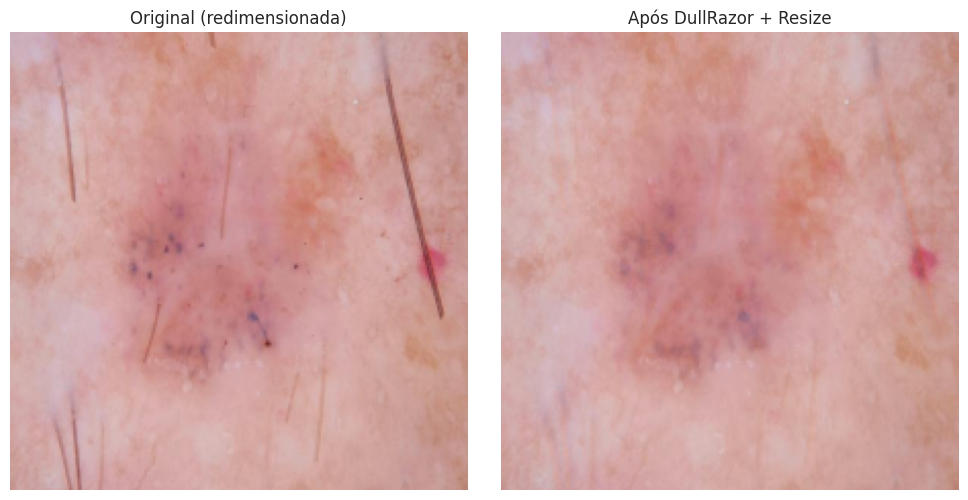

Exemplo salvo em: /content/data/processed/exemplo_dullrazor.png

Dividindo em treino / validação / teste
Agrupamento primário: lesion_id | registros sem lesion_id: 1663
Calculando pHash das imagens para localizar duplicidades perceptuais...


pHash: 100%|██████████| 23391/23391 [05:40<00:00, 68.78it/s] 


treino: 16447 imagens | 9011 grupos | classes={'nevo_melanocitico': 9012, 'melanoma': 3245, 'carcinoma_basocelular': 2286, 'ceratose_seborreica': 948, 'ceratose_actinica': 611, 'dermatofibroma': 177, 'lesao_vascular': 168}
validacao: 3538 imagens | 1931 grupos | classes={'nevo_melanocitico': 1956, 'melanoma': 670, 'carcinoma_basocelular': 538, 'ceratose_seborreica': 171, 'ceratose_actinica': 130, 'lesao_vascular': 40, 'dermatofibroma': 33}
teste: 3406 imagens | 1931 grupos | classes={'nevo_melanocitico': 1903, 'melanoma': 607, 'carcinoma_basocelular': 499, 'ceratose_seborreica': 197, 'ceratose_actinica': 126, 'lesao_vascular': 45, 'dermatofibroma': 29}
Candidatos pHash avaliados: 190 | rejeitados pelo histograma de cor: 27
Pares perceptuais confirmados e agrupados (não removidos): 163
Auditoria salva em: /content/data/processed/split_audit.csv
Pares perceptuais salvos em: /content/data/processed/perceptual_duplicates.csv

Processando e salvando imagens (DullRazor + resize)


Processando test: 100%|██████████| 3406/3406 [08:21<00:00,  6.79it/s]



CONCLUÍDO
Treino: 16447 imagens processadas
Validação: 3538 imagens processadas
Teste: 3406 imagens processadas

Distribuição de classes no treino:
classe
nevo_melanocitico        9012
melanoma                 3245
carcinoma_basocelular    2286
ceratose_seborreica       948
ceratose_actinica         611
dermatofibroma            177
lesao_vascular            168
Name: count, dtype: int64


In [ ]:
# ============================================================
# EXECUÇÃO
# ============================================================
if __name__ == "__main__":
    print("=" * 60)
    print("Carregando dataset limpo")
    print("=" * 60)
    df = pd.read_csv(ENTRADA_CSV)
    print(f"Total de registros: {len(df)}")

    print("\n" + "=" * 60)
    print("Exemplo visual do DullRazor (conferência antes de processar tudo)")
    print("=" * 60)
    visualizar_exemplo_dullrazor(df, indice=0)

    print("\n" + "=" * 60)
    print("Dividindo em treino / validação / teste")
    print("=" * 60)
    df_treino, df_val, df_teste = dividir_dataset(df)

    print("\n" + "=" * 60)
    print("Processando e salvando imagens (DullRazor + resize)")
    print("=" * 60)
    df_treino_proc = processar_e_salvar(df_treino, "train")
    df_val_proc = processar_e_salvar(df_val, "val")
    df_teste_proc = processar_e_salvar(df_teste, "test")

    # Salva os CSVs finais de cada split — serão a entrada do DataLoader
    df_treino_proc.to_csv(os.path.join(SAIDA_BASE, "train.csv"), index=False)
    df_val_proc.to_csv(os.path.join(SAIDA_BASE, "val.csv"), index=False)
    df_teste_proc.to_csv(os.path.join(SAIDA_BASE, "test.csv"), index=False)

    print("\n" + "=" * 60)
    print("CONCLUÍDO")
    print("=" * 60)
    print(f"Treino: {len(df_treino_proc)} imagens processadas")
    print(f"Validação: {len(df_val_proc)} imagens processadas")
    print(f"Teste: {len(df_teste_proc)} imagens processadas")
    print(f"\nDistribuição de classes no treino:")
    print(df_treino_proc["classe"].value_counts())

### Pré-processamento — versões com/sem DullRazor, figuras e padronização (acréscimos)

Esta seção acrescenta, sem alterar o que já existia:

1. **Versão "sem DullRazor"** das mesmas imagens e do **mesmo split** (só redimensionadas), usada no teste A/B de remoção de pelos.
2. **Figuras antes/depois** do pré-processamento em treino, validação e teste.
3. **Análise de artefatos**: quanto do pixel é alterado pelo DullRazor, por classe, e se a alteração se concentra no centro da imagem (onde fica a lesão).
4. **Verificação de padronização**: prova que a filtragem é idêntica nos três conjuntos e salva o `pipeline_config.json`.

In [ ]:
# ============================================================
# VERSÃO "SEM DULLRAZOR" — imagens originais, apenas redimensionadas
# Usa exatamente os mesmos registros/split de train.csv, val.csv e test.csv
# ============================================================
SUBPASTA_SEM_DR = "sem_dullrazor"

def gerar_dataset_sem_dullrazor():
    col_id = None
    for split in ["train", "val", "test"]:
        df_split = pd.read_csv(os.path.join(SAIDA_BASE, f"{split}.csv"), low_memory=False)
        col_id = col_id or identificar_coluna_id(df_split)

        df_origem = df_split.drop(columns=["caminho_processado"])
        df_proc = processar_e_salvar(df_origem, split, aplicar_dullrazor=False,
                                     subpasta=SUBPASTA_SEM_DR)
        df_proc.to_csv(os.path.join(SAIDA_BASE, f"{split}_{SUBPASTA_SEM_DR}.csv"), index=False)

        mesmo_split = set(df_proc[col_id]) == set(df_split[col_id])
        print(f"[{split}] {len(df_proc)} imagens sem DullRazor | "
              f"mesmo conjunto de imagens que a versão com DullRazor: "
              f"{'SIM' if mesmo_split else 'NÃO (verifique falhas acima)'}")

if __name__ == "__main__":
    gerar_dataset_sem_dullrazor()

Processando train: 100%|██████████| 16447/16447 [04:20<00:00, 63.19it/s] 


[train] 16447 imagens sem DullRazor | mesmo conjunto de imagens que a versão com DullRazor: SIM


Processando val: 100%|██████████| 3538/3538 [00:57<00:00, 61.32it/s] 


[val] 3538 imagens sem DullRazor | mesmo conjunto de imagens que a versão com DullRazor: SIM


Processando test: 100%|██████████| 3406/3406 [00:57<00:00, 59.15it/s] 


[test] 3406 imagens sem DullRazor | mesmo conjunto de imagens que a versão com DullRazor: SIM


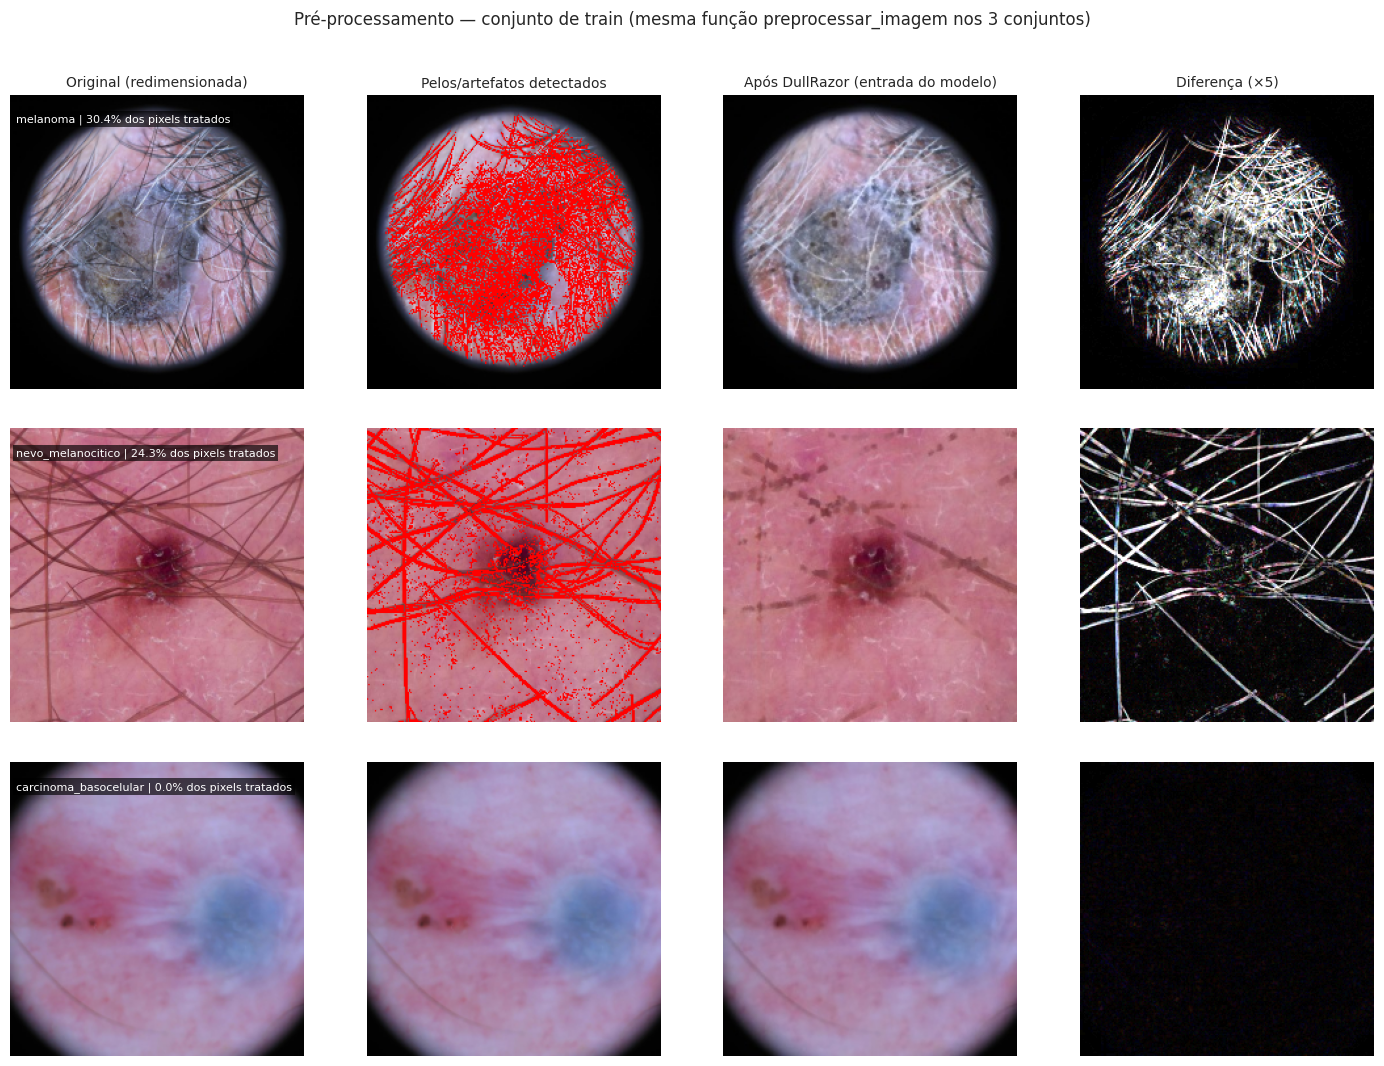

Figura salva em: /content/data/processed/figura_preprocessamento_train.png


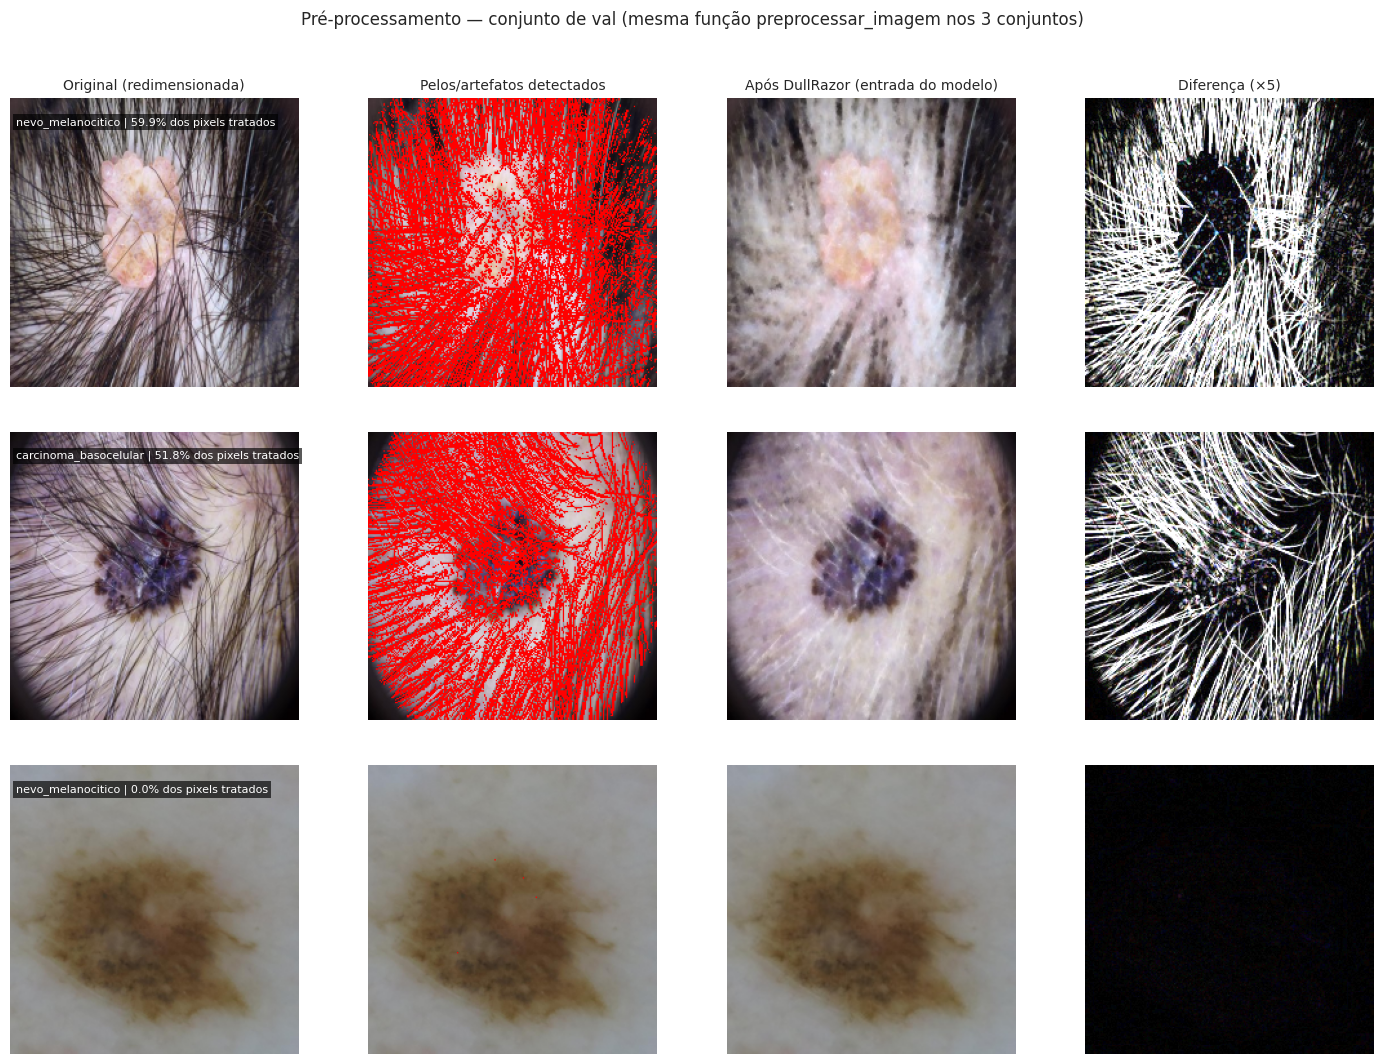

Figura salva em: /content/data/processed/figura_preprocessamento_val.png


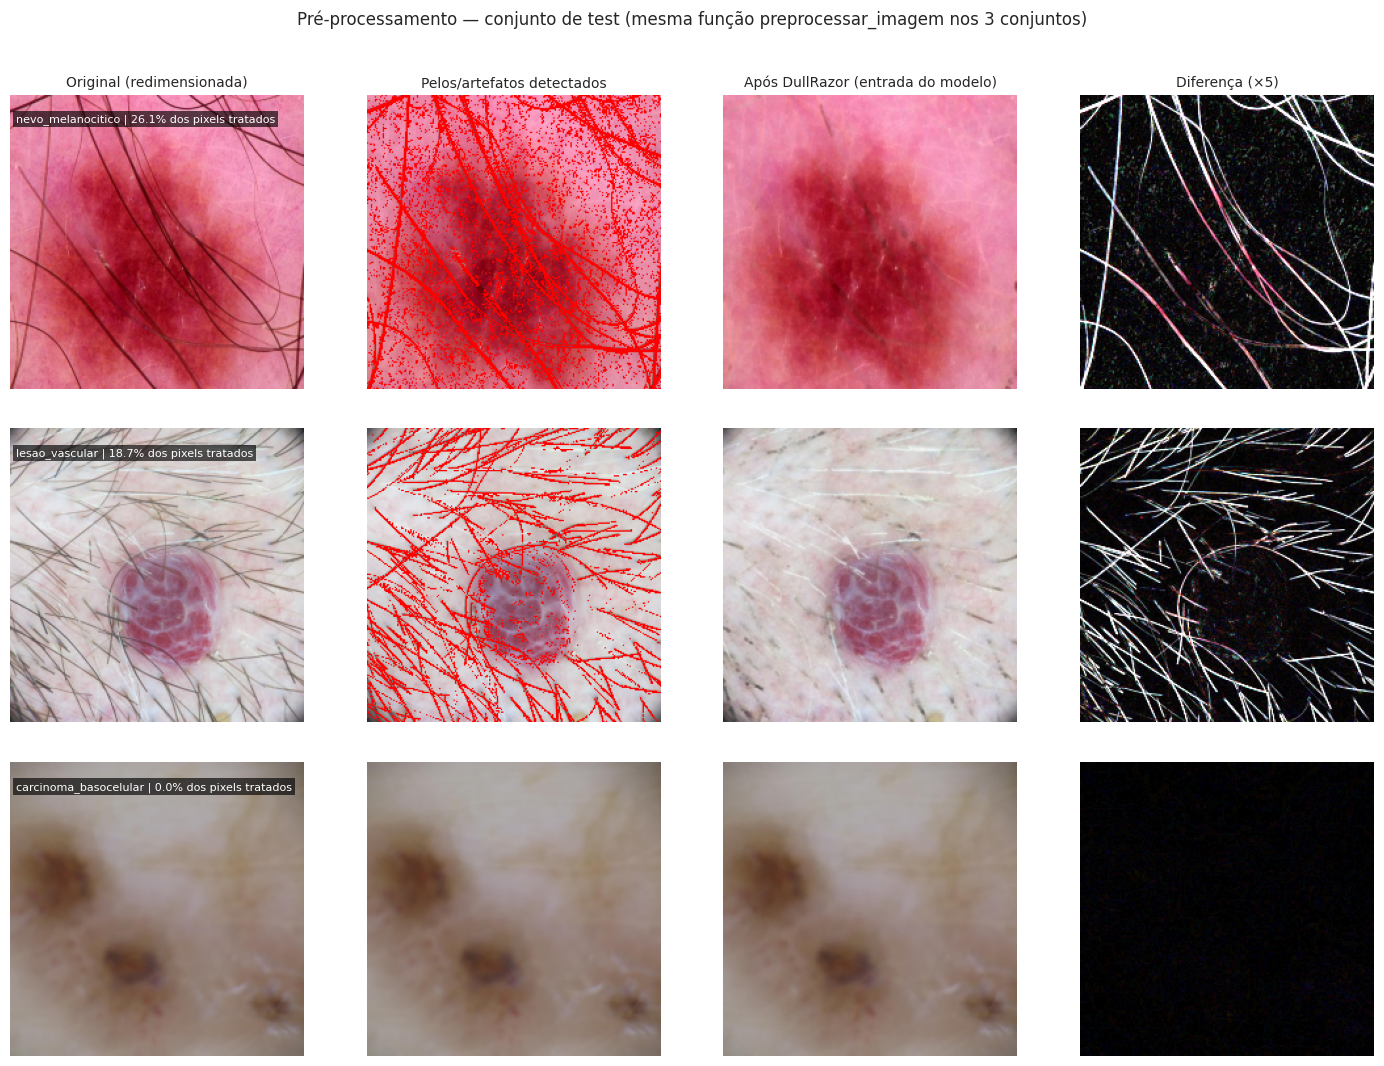

Figura salva em: /content/data/processed/figura_preprocessamento_test.png


In [ ]:
# ============================================================
# FIGURAS DE PRÉ-PROCESSAMENTO (antes/depois) — TREINO, VALIDAÇÃO E TESTE
# ============================================================
N_AMOSTRA_PELOS = 300   # imagens por split para medir a fração de pixels tratados

def calcular_fracao_pelos(df_split, n=N_AMOSTRA_PELOS, seed=SEED):
    """Mede, na imagem ORIGINAL, que fração dos pixels o DullRazor marca como pelo/artefato
    (total, região central e periferia). Só calcula a máscara (rápido), sem inpainting."""
    amostra = df_split.sample(n=min(n, len(df_split)), random_state=seed).copy()
    total, centro_l, borda_l = [], [], []
    for caminho in tqdm(amostra["caminho_imagem"], desc="Máscara de pelos", leave=False):
        img = cv2.imread(caminho)
        if img is None:
            total.append(np.nan); centro_l.append(np.nan); borda_l.append(np.nan)
            continue
        m = mascara_pelos(img) > 0
        h, w = m.shape
        centro = np.zeros_like(m)
        centro[h // 4: 3 * h // 4, w // 4: 3 * w // 4] = True
        total.append(m.mean())
        centro_l.append(m[centro].mean())
        borda_l.append(m[~centro].mean())
    amostra["frac_mascara"] = total
    amostra["frac_centro"] = centro_l
    amostra["frac_borda"] = borda_l
    return amostra.dropna(subset=["frac_mascara"])


def figura_antes_depois(amostra, nome_split, n_com_pelos=2, n_sem_pelos=1):
    """Linhas = exemplos (os mais e o menos afetados pelo DullRazor no split).
    Colunas = original | pelos detectados | após DullRazor (o que entra no modelo) | diferença."""
    ordenado = amostra.sort_values("frac_mascara", ascending=False)
    escolhidas = pd.concat([ordenado.head(n_com_pelos), ordenado.tail(n_sem_pelos)])

    fig, eixos = plt.subplots(len(escolhidas), 4, figsize=(14, 3.6 * len(escolhidas)))
    titulos = ["Original (redimensionada)", "Pelos/artefatos detectados",
               "Após DullRazor (entrada do modelo)", "Diferença (×5)"]

    for i, (_, r) in enumerate(escolhidas.iterrows()):
        img = cv2.imread(r["caminho_imagem"])
        original = preprocessar_imagem(img, aplicar_dullrazor=False)
        mascara = cv2.resize(mascara_pelos(img), (TAMANHO_IMAGEM, TAMANHO_IMAGEM),
                             interpolation=cv2.INTER_NEAREST) > 0
        tratada = cv2.imread(r["caminho_processado"])   # exatamente o arquivo usado no treino/teste

        sobreposta = original.copy()
        sobreposta[mascara] = (0, 0, 255)   # BGR: vermelho
        diferenca = np.clip(cv2.absdiff(original, tratada).astype(np.int32) * 5, 0, 255).astype(np.uint8)

        for j, im in enumerate([original, sobreposta, tratada, diferenca]):
            eixos[i, j].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
            eixos[i, j].axis("off")
            if i == 0:
                eixos[i, j].set_title(titulos[j], fontsize=10)
        eixos[i, 0].text(4, 14, f"{r['classe']} | {r['frac_mascara']:.1%} dos pixels tratados",
                         fontsize=8, color="white", va="top",
                         bbox=dict(facecolor="black", alpha=0.65, pad=2, edgecolor="none"))

    fig.suptitle(f"Pré-processamento — conjunto de {nome_split} "
                 f"(mesma função preprocessar_imagem nos 3 conjuntos)", fontsize=12, y=1.0)
    plt.tight_layout()
    caminho = os.path.join(SAIDA_BASE, f"figura_preprocessamento_{nome_split}.png")
    plt.savefig(caminho, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Figura salva em: {caminho}")


AMOSTRAS_PELOS = {}
if __name__ == "__main__":
    for nome_split in ["train", "val", "test"]:
        df_s = pd.read_csv(os.path.join(SAIDA_BASE, f"{nome_split}.csv"), low_memory=False)
        AMOSTRAS_PELOS[nome_split] = calcular_fracao_pelos(df_s)
        figura_antes_depois(AMOSTRAS_PELOS[nome_split], nome_split)

--- Pixels tratados pelo DullRazor, por classe (amostra) ---
                         n  pct_pixels_media  pct_pixels_mediana  pct_imgs_acima_5pct  razao_centro_borda_mediana
classe                                                                                                           
carcinoma_basocelular  165              2.55                0.89                13.33                        3.45
ceratose_actinica       29              1.74                1.01                 6.90                        3.89
ceratose_seborreica     47              3.55                0.96                21.28                        2.87
dermatofibroma          13              1.72                1.10                 7.69                        3.67
lesao_vascular          12              3.28                0.74                25.00                        5.10
melanoma               160              3.56                1.94                23.75                        3.46
nevo_melanocitico      474 

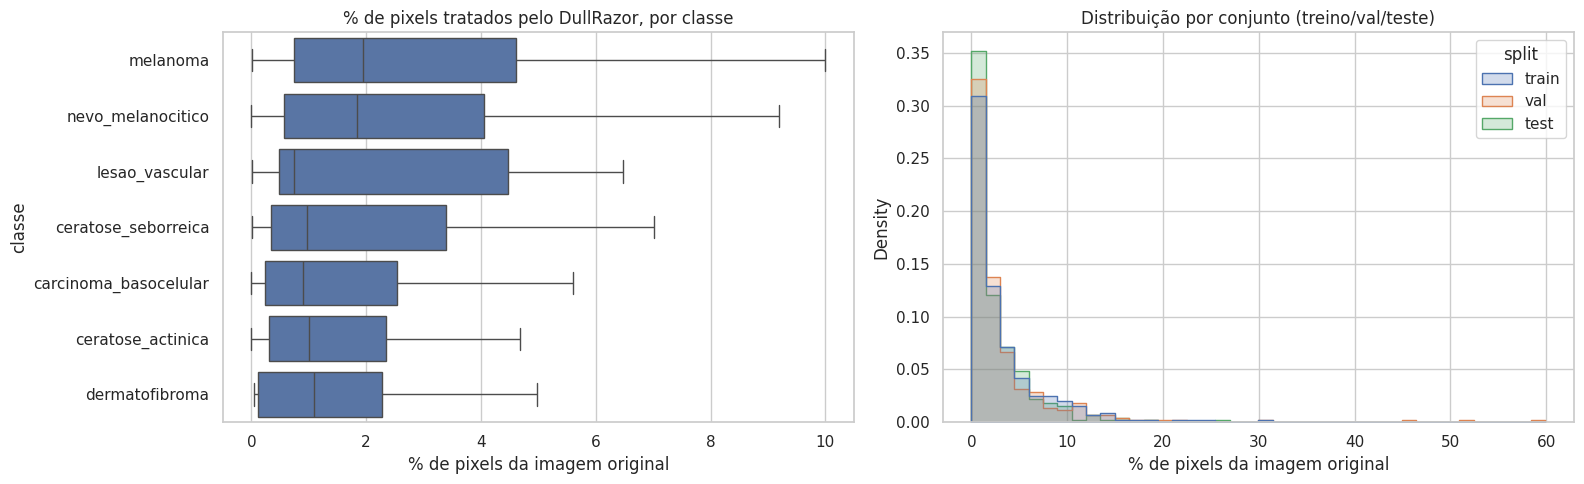


Como interpretar:
 - Se a razão centro/borda for >> 1, o DullRazor está mexendo mais no centro (onde fica a lesão)
   do que na periferia: sinal de que pode estar apagando estruturas da própria lesão
   (rede pigmentar, pontos/glóbulos) em vez de apenas pelos.
 - Classes com muito mais pixels tratados (ex.: melanoma/nevo, lesões escuras) merecem atenção.
 - O efeito real sobre o desempenho é medido no Teste A/B (com x sem DullRazor), adiante.


In [ ]:
# ============================================================
# ANÁLISE DE ARTEFATOS DO DULLRAZOR — ele altera sinais da lesão?
# ============================================================
def analisar_artefatos_dullrazor(amostras):
    df = pd.concat([a.assign(split=s) for s, a in amostras.items()], ignore_index=True)
    df["pct_pixels_tratados"] = df["frac_mascara"] * 100
    df["razao_centro_borda"] = df["frac_centro"] / (df["frac_borda"] + 1e-9)

    por_classe = df.groupby("classe").agg(
        n=("frac_mascara", "size"),
        pct_pixels_media=("pct_pixels_tratados", "mean"),
        pct_pixels_mediana=("pct_pixels_tratados", "median"),
        pct_imgs_acima_5pct=("pct_pixels_tratados", lambda x: (x > 5).mean() * 100),
        razao_centro_borda_mediana=("razao_centro_borda", "median"),
    ).round(2)
    print("--- Pixels tratados pelo DullRazor, por classe (amostra) ---")
    print(por_classe.to_string())

    por_split = df.groupby("split").agg(
        n=("frac_mascara", "size"),
        pct_pixels_media=("pct_pixels_tratados", "mean"),
        pct_pixels_mediana=("pct_pixels_tratados", "median"),
    ).round(2)
    print("\n--- Mesma distribuição nos três conjuntos? (padronização) ---")
    print(por_split.to_string())

    fig, eixos = plt.subplots(1, 2, figsize=(16, 5))
    sns.boxplot(data=df, y="classe", x="pct_pixels_tratados", ax=eixos[0], showfliers=False)
    eixos[0].set_title("% de pixels tratados pelo DullRazor, por classe")
    eixos[0].set_xlabel("% de pixels da imagem original")
    sns.histplot(data=df, x="pct_pixels_tratados", hue="split", bins=40,
                 stat="density", common_norm=False, element="step", ax=eixos[1])
    eixos[1].set_title("Distribuição por conjunto (treino/val/teste)")
    eixos[1].set_xlabel("% de pixels da imagem original")
    plt.tight_layout()
    caminho = os.path.join(SAIDA_BASE, "analise_artefatos_dullrazor.png")
    plt.savefig(caminho, dpi=150)
    plt.show()
    por_classe.to_csv(os.path.join(SAIDA_BASE, "analise_artefatos_dullrazor_por_classe.csv"))

    print("\nComo interpretar:")
    print(" - Se a razão centro/borda for >> 1, o DullRazor está mexendo mais no centro (onde fica a lesão)")
    print("   do que na periferia: sinal de que pode estar apagando estruturas da própria lesão")
    print("   (rede pigmentar, pontos/glóbulos) em vez de apenas pelos.")
    print(" - Classes com muito mais pixels tratados (ex.: melanoma/nevo, lesões escuras) merecem atenção.")
    print(" - O efeito real sobre o desempenho é medido no Teste A/B (com x sem DullRazor), adiante.")
    return por_classe, por_split

if __name__ == "__main__":
    if AMOSTRAS_PELOS:
        analisar_artefatos_dullrazor(AMOSTRAS_PELOS)
    else:
        print("[AVISO] Rode antes a célula das figuras de pré-processamento (AMOSTRAS_PELOS vazio).")

In [ ]:
import json

# ============================================================
# VERIFICAÇÃO DE PADRONIZAÇÃO — mesma filtragem em treino, validação e teste
# ============================================================
def verificar_padronizacao(n_por_split=15):
    """Reaplica preprocessar_imagem a uma amostra de cada conjunto e confere, pixel a pixel,
    se o arquivo salvo em disco é exatamente o resultado esperado (prova de que o pipeline
    é determinístico e idêntico nos três conjuntos)."""
    registros = []
    variantes = [("com_dullrazor", True, ""), ("sem_dullrazor", False, f"_{SUBPASTA_SEM_DR}")]
    for nome_versao, aplicar, sufixo in variantes:
        for split in ["train", "val", "test"]:
            caminho_csv = os.path.join(SAIDA_BASE, f"{split}{sufixo}.csv")
            if not os.path.exists(caminho_csv):
                continue
            df = pd.read_csv(caminho_csv, low_memory=False)
            amostra = df.sample(n=min(n_por_split, len(df)), random_state=SEED)
            iguais = 0
            for _, r in amostra.iterrows():
                esperado = preprocessar_imagem(cv2.imread(r["caminho_imagem"]), aplicar_dullrazor=aplicar)
                # o arquivo em disco passou por compressão JPEG: aplica a mesma compressão ao esperado
                esperado = cv2.imdecode(cv2.imencode(".jpg", esperado, PARAMS_JPEG)[1], cv2.IMREAD_COLOR)
                salvo = cv2.imread(r["caminho_processado"])
                iguais += int(salvo is not None and np.array_equal(esperado, salvo))
            registros.append({
                "versao": nome_versao, "conjunto": split, "n_imagens": len(df),
                "verificadas": len(amostra), "identicas_ao_pipeline": iguais,
            })

    df_verif = pd.DataFrame(registros)
    print(df_verif.to_string(index=False))

    config = {
        "funcao_unica": "preprocessar_imagem(img, aplicar_dullrazor)",
        "aplicado_em": ["train", "val", "test"],
        "dullrazor": {"kernel_blackhat": DR_KERNEL, "limiar_binarizacao": DR_LIMIAR,
                      "inpaint_raio": DR_RAIO_INPAINT, "inpaint_metodo": "TELEA"},
        "resize": {"tamanho": TAMANHO_IMAGEM, "interpolacao": "INTER_AREA"},
        "jpeg_qualidade": PARAMS_JPEG[1],
        "split": {"seed": SEED, "treino": PROPORCAO_TREINO, "val": PROPORCAO_VAL,
                  "teste": PROPORCAO_TESTE, "inclui_sem_lesion_id": INCLUIR_SEM_LESION_ID,
                  "agrupamento_primario": "lesion_id",
                  "duplicidade_perceptual": "pHash DCT 64-bit, distância de Hamming <= PHASH_DISTANCIA_MAX; grupos unidos, não removidos"},
        "normalizacao_e_augmentation": "feitas dinamicamente no DataLoader (não no disco): "
                                       "eval_transform (val/teste) = só normalização ImageNet; "
                                       "augmentation apenas no treino",
        "verificacao_pixel_a_pixel": df_verif.to_dict(orient="records"),
    }
    caminho = os.path.join(SAIDA_BASE, "pipeline_config.json")
    with open(caminho, "w") as f:
        json.dump(config, f, indent=2, ensure_ascii=False, default=int)

    todas_ok = bool((df_verif["verificadas"] == df_verif["identicas_ao_pipeline"]).all()) if len(df_verif) else False
    print("\nREGISTRO PARA O TCC:")
    print(f"  A filtragem (DullRazor: kernel {DR_KERNEL}x{DR_KERNEL}, limiar {DR_LIMIAR}, inpainting TELEA raio {DR_RAIO_INPAINT}; "
          f"resize {TAMANHO_IMAGEM}x{TAMANHO_IMAGEM}, INTER_AREA) é aplicada pela mesma função e com os mesmos")
    print("  parâmetros em treino, validação e teste. Normalização e augmentation não são gravados em disco.")
    print(f"  Verificação pixel a pixel: {'APROVADA' if todas_ok else 'REVISAR (há divergências na tabela)'}.")
    print(f"  Configuração salva em: {caminho}")
    return df_verif

if __name__ == "__main__":
    verificar_padronizacao()

       versao conjunto  n_imagens  verificadas  identicas_ao_pipeline
com_dullrazor    train      16447           15                     15
com_dullrazor      val       3538           15                     15
com_dullrazor     test       3406           15                     15
sem_dullrazor    train      16447           15                     15
sem_dullrazor      val       3538           15                     15
sem_dullrazor     test       3406           15                     15

REGISTRO PARA O TCC:
  A filtragem (DullRazor: kernel 9x9, limiar 10, inpainting TELEA raio 3; resize 224x224, INTER_AREA) é aplicada pela mesma função e com os mesmos
  parâmetros em treino, validação e teste. Normalização e augmentation não são gravados em disco.
  Verificação pixel a pixel: APROVADA.
  Configuração salva em: /content/data/processed/pipeline_config.json
